In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

In [11]:
df = pd.read_csv(r"D:\1_Python Programmes\Projects\HDD\data\heart_disease_cleaned.csv")

X = df.drop(columns = ["id","dataset","num"])
y = df["num"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

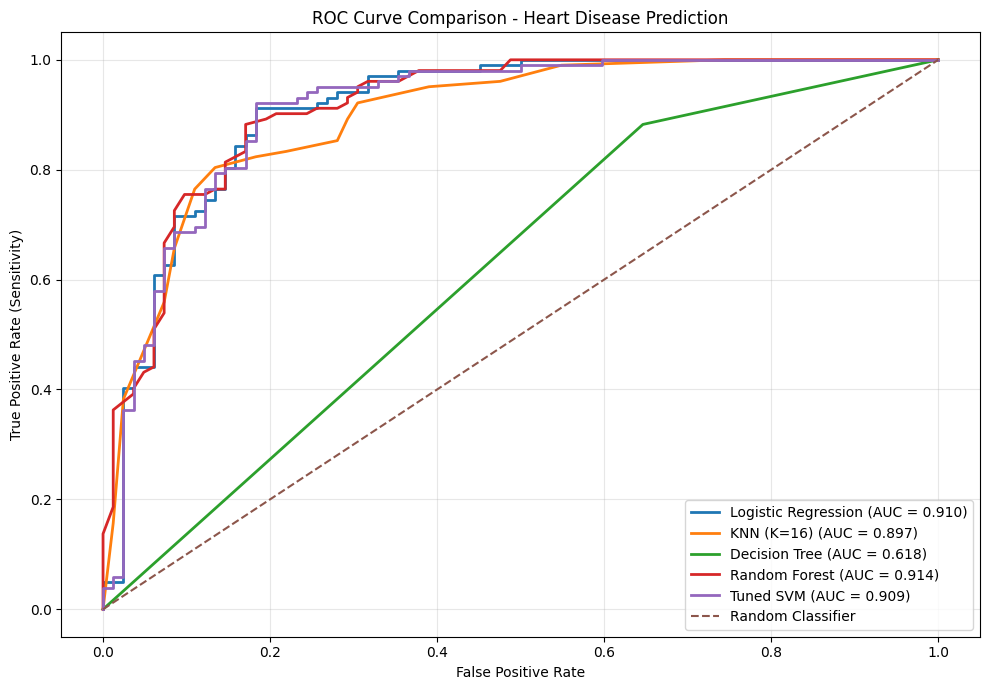

In [13]:
lr_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/logistic_r_model.pkl")
knn_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/heart_disease_knn.pkl")
dt_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/decision_tree_model.pkl")
rf_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/random_forest_model.pkl")
svm_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/svm_model.pkl")

models = {
    "Logistic Regression": lr_model,
    "KNN (K=16)": knn_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Tuned SVM": svm_model
}

plt.figure(figsize=(10, 7))

for name, artifact in models.items():

    # Handle dictionary-based model artifacts
    model = artifact["model"] if isinstance(artifact, dict) else artifact

    # Get probability of positive class (heart disease = 1)
    classes = model.classes_
    positive_index = np.where(classes == 1)[0][0]

    y_prob = model.predict_proba(X_test)[:, positive_index]

    # Calculate ROC
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    roc_auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curve Comparison - Heart Disease Prediction")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

# plt.savefig("D:/1_Python Programmes/Projects/HDD/reports/roc_curve_comparison.png", dpi=300)
plt.show()

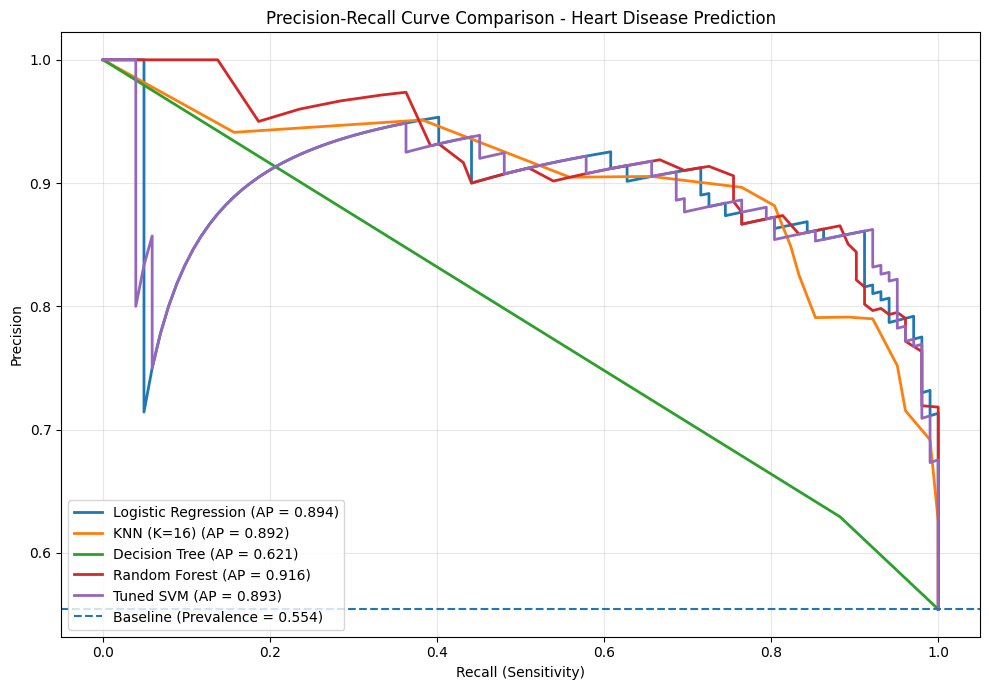

In [14]:
plt.figure(figsize=(10, 7))

for name, artifact in models.items():

    model = artifact["model"] if isinstance(artifact, dict) else artifact

    classes = model.classes_
    positive_index = np.where(classes == 1)[0][0]

    y_prob = model.predict_proba(X_test)[:, positive_index]

    # Calculate Precision-Recall
    precision, recall, thresholds = precision_recall_curve(
        y_test,
        y_prob
    )

    # Calculate Average Precision
    ap = average_precision_score(y_test, y_prob)

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP = {ap:.3f})"
    )

# Baseline: positive class prevalence
baseline = np.mean(y_test)

plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Baseline (Prevalence = {baseline:.3f})"
)

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison - Heart Disease Prediction")

plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("D:/1_Python Programmes/Projects/HDD/reports/pr_curve_comparison.png", dpi=300)
plt.show()